# Red neuronal: valor de la call asiática en cada trimestre

Queremos una red que, viendo la trayectoria de WMT, MRK y NVDA **hasta el trimestre t**, diga cuánto vale la opción en ese momento. El objetivo es el valor presente del payoff en ese instante:

$$Y_t = V_T \cdot e^{-\mu (n - t)\Delta t}$$

Con la trayectoria completa (t = 20) el payoff sale de una fórmula y la red no aporta nada. Donde sí aporta es en los instantes intermedios. Para saber cuánto vale la opción en el trimestre 8 de un camino concreto, Montecarlo tiene que simular de nuevo miles de futuros desde ese punto, y repetirlo para cada camino y cada trimestre. La red hace ese cálculo en una sola pasada.

Si la red se entrena con error cuadrático medio (MSE) sobre el payoff de cada simulación, aprende la **media del payoff condicionada a lo que ha visto**, que es justo el valor de la opción en ese instante.

Pasos del notebook:
1. Parámetros (los mismos que el Montecarlo).
2. Datos: 50 comienzos × 2.000 continuaciones.
3. Entradas y objetivos de la red.
4. Train, validación y test por comienzo.
5. Modelos: MLP (base), GRU y LSTM.
6. Entrenamiento con early stopping.
7. Valor de referencia con Montecarlo anidado.
8. Comparación de modelos: error y tiempo.
9. Objetivo alternativo: predecir las medias geométricas.
10. Comprobación con el comienzo del Hito 1 (semilla 11).

## 1. Parámetros

Son los mismos que en **montecarlo_verdeclaro.ipynb**.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

acciones = ["WMT", "MRK", "NVDA"]
S0 = np.array([1.0, 1.0, 1.0])      # precios iniciales normalizados
mu = 0.01                           # tasa libre de riesgo
E = 3.0                             # strike de la cesta
T = 5                               # años
n_times = 20                        # trimestres en total
n_comunes = 5                       # trimestres del comienzo
n_resto = n_times - n_comunes       # 15
dt = T / n_times                    # 0,25 años

sigma = np.array([0.21915220410541955, 0.23593283496457446, 0.5174176492623017])
rho = np.array([[1.0,                 0.23448266076590554, 0.2254536587614545 ],
                [0.23448266076590554, 1.0,                 0.12948744681423088],
                [0.2254536587614545,  0.12948744681423088, 1.0                ]])
L = np.linalg.cholesky(rho)

COLORES = {
    "azul_principal":  "#001391",
    "azul_claro":      "#4D5FC4",
    "azul_muy_claro":  "#B3BAE8",
    "gris_oscuro":     "#1A1A2E",
    "gris_medio":      "#6E7191",
    "gris_claro":      "#E4E4EC",
    "blanco":          "#FFFFFF",
    "acento":          "#FF4B4B",
}

torch.manual_seed(0)
rng = np.random.default_rng(2026)
Path("modelos").mkdir(exist_ok=True)

## 2. Datos: 50 comienzos × 2.000 continuaciones

Mantenemos la idea del Montecarlo: los 5 primeros trimestres son un camino común y desde el trimestre 5 la trayectoria se abre. La diferencia es que aquí lo repetimos con **50 comienzos distintos**, cada uno con 2.000 continuaciones (100.000 simulaciones en total).

Con un solo comienzo, en los trimestres 1 a 5 la red vería 100.000 veces la misma entrada y no podría aprender nada ahí. Además, solo sabría valorar caminos que pasan por ese punto concreto. Con 50 comienzos ve situaciones de partida distintas.

El precio se calcula igual que en el Montecarlo: $S_{t+1} = S_t \cdot e^{(\mu - \sigma^2/2)\Delta t + \sigma Z \sqrt{\Delta t}}$, con $Z$ correlacionado con Cholesky.

In [2]:
n_comienzos = 50
n_por_comienzo = 2_000
n_sims = n_comienzos * n_por_comienzo

def factores(rng, forma):
    # factor e^{(mu - sigma^2/2) dt + sigma Z sqrt(dt)} con Z correlacionado; forma + (3,)
    Z = rng.standard_normal(forma + (3,)) @ L.T
    return np.exp((mu - 0.5 * sigma**2) * dt + sigma * Z * np.sqrt(dt))

X = np.empty((n_comienzos, n_por_comienzo, n_times, 3))
for c in range(n_comienzos):
    comienzo = S0 * np.cumprod(factores(rng, (n_comunes,)), axis=0)                    # (5, 3)
    resto = comienzo[-1] * np.cumprod(factores(rng, (n_por_comienzo, n_resto)), axis=1)  # (2000, 15, 3)
    X[c, :, :n_comunes] = comienzo
    X[c, :, n_comunes:] = resto

X = X.reshape(n_sims, n_times, 3)                          # (100.000, 20, 3), igual que en el Montecarlo
grupo = np.repeat(np.arange(n_comienzos), n_por_comienzo)  # a qué comienzo pertenece cada simulación

G = np.exp(np.log(X).mean(axis=1))      # media geométrica de los 20 precios de cada acción: (n_sims, 3)
payoff = np.maximum(G.sum(axis=1) - E, 0)
print("Dimensión de X:", X.shape)
print(f"Payoff medio: {payoff.mean():.4f} | simulaciones con payoff 0: {(payoff == 0).mean():.1%}")

Dimensión de X: (100000, 20, 3)
Payoff medio: 0.4642 | simulaciones con payoff 0: 50.9%


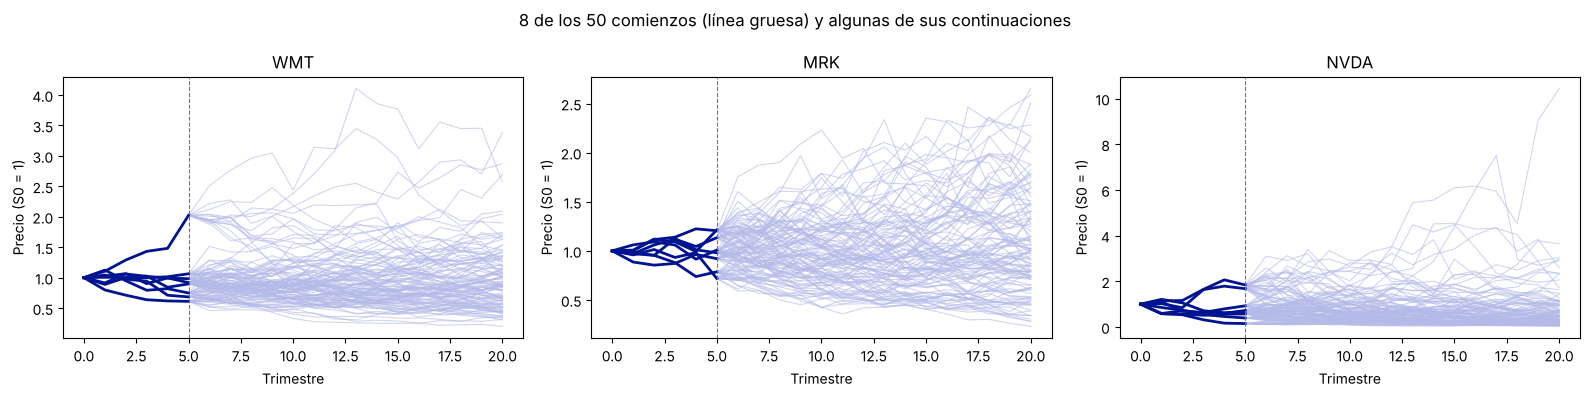

In [3]:
t1 = np.arange(0, n_comunes + 1)
t2 = np.arange(n_comunes, n_times + 1)
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
for k, ax in enumerate(ejes):
    for c in range(8):                                   # 8 comienzos con 15 continuaciones cada uno
        sims = X[grupo == c][:15, :, k]
        ax.plot(t2, np.column_stack([sims[:, n_comunes - 1], sims[:, n_comunes:]]).T,
                color=COLORES["azul_muy_claro"], lw=0.8, alpha=0.6)
        ax.plot(t1, np.r_[1.0, sims[0, :n_comunes]], color=COLORES["azul_principal"], lw=2)
    ax.axvline(n_comunes, color=COLORES["gris_medio"], lw=0.8, ls="--")
    ax.set_title(acciones[k]); ax.set_xlabel("Trimestre"); ax.set_ylabel("Precio (S0 = 1)")
fig.suptitle("8 de los 50 comienzos (línea gruesa) y algunas de sus continuaciones")
plt.tight_layout()
plt.show()

## 3. Entradas y objetivos

**Objetivo.** Para cada simulación y cada trimestre t = 1…20, el payoff traído al instante t: $Y_t = V_T \, e^{-\mu (20 - t)\Delta t}$. La red da una predicción por trimestre (many-to-many).

**Entradas.** Usamos $\log X$ en vez de $X$: los precios van de 0,01 a más de 50, mientras que $\log X$ tiene media cercana a 0 y desviación en torno a 0,6, que es la escala con la que mejor entrena una red.

- **GRU y LSTM** solo reciben $\log X$ (3 variables por trimestre). Tienen que recordar ellas mismas la parte del camino que ya ha pasado, y para eso sirven las redes recurrentes.
- **MLP (red densa)** no tiene memoria, así que le damos el resumen hecho: el log del precio actual, la media de los logs hasta t (la media geométrica acumulada) y t/20, es decir, 7 variables por trimestre. Con eso tiene toda la información que necesita. Es la referencia con la que comparamos las recurrentes.

In [4]:
logX = np.log(X)                                                           # (n_sims, 20, 3)
pasos = np.arange(1, n_times + 1)                                          # t = 1..20
media_log = np.cumsum(logX, axis=1) / pasos[None, :, None]                 # log de la media geométrica hasta t
tiempo = np.broadcast_to((pasos / n_times)[None, :, None], (n_sims, n_times, 1))

entrada_rnn = logX                                                         # (n_sims, 20, 3)
entrada_mlp = np.concatenate([logX, media_log, tiempo], axis=2)            # (n_sims, 20, 7)

descuento = np.exp(-mu * (n_times - pasos) * dt)                           # (20,)
Y = payoff[:, None] * descuento[None, :]                                   # (n_sims, 20)

print("Entrada RNN:", entrada_rnn.shape, "| Entrada MLP:", entrada_mlp.shape, "| Objetivo:", Y.shape)
print(f"log X: media {logX.mean():.3f}, desviación {logX.std():.3f}")

Entrada RNN: (100000, 20, 3) | Entrada MLP: (100000, 20, 7) | Objetivo: (100000, 20)
log X: media -0.062, desviación 0.595


## 4. Train, validación y test por comienzo

Separamos por **comienzo**, no por simulación: 40 comienzos para entrenar, 5 para validación y 5 para test. Si separásemos por simulación, la red vería en el entrenamiento los mismos 5 primeros trimestres que luego evaluamos en test, y el test sería demasiado fácil. Así, el test son comienzos que la red no ha visto nunca.

In [5]:
orden = rng.permutation(n_comienzos)
comienzos = {"train": orden[:40], "val": orden[40:45], "test": orden[45:]}
filas = {parte: np.isin(grupo, ids) for parte, ids in comienzos.items()}

def a_tensor(a):
    return torch.tensor(np.ascontiguousarray(a), dtype=torch.float32)

datos = {}
for parte, f in filas.items():
    datos[parte] = {"rnn": a_tensor(entrada_rnn[f]), "mlp": a_tensor(entrada_mlp[f]), "Y": a_tensor(Y[f])}
    print(f"{parte:5s}: {f.sum():6d} simulaciones de los comienzos {sorted(comienzos[parte].tolist())[:6]}{'...' if parte == 'train' else ''}")

train:  80000 simulaciones de los comienzos [0, 1, 2, 3, 4, 5]...
val  :  10000 simulaciones de los comienzos [16, 21, 22, 30, 33]
test :  10000 simulaciones de los comienzos [8, 17, 20, 41, 44]


## 5. Modelos

Comparamos tres topologías. Todas tienen 64 neuronas por capa oculta y una salida **Softplus**, porque el valor de una call nunca es negativo y Softplus, a diferencia de ReLU, no deja el gradiente a 0.

| Modelo | Qué es | Por qué lo probamos |
|---|---|---|
| MLP | 2 capas densas + ReLU, aplicadas a cada trimestre por separado | Lo visto en clase. Es la referencia. |
| GRU | Recurrente de 2 capas | Tiene memoria y menos parámetros que la LSTM. |
| LSTM | Recurrente de 2 capas | La memoria más completa (celda + 3 puertas). |

La red recurrente lee la trayectoria trimestre a trimestre y da una salida en cada paso, que solo depende de lo que ha visto hasta ese momento. Por eso no hace falta tratar aparte las longitudes distintas: la salida del paso t ya es la predicción para una trayectoria de longitud t.

In [6]:
class MLP(nn.Module):
    def __init__(self, n_entradas, n_salidas, ocultas=64):
        super().__init__()
        self.red = nn.Sequential(
            nn.Linear(n_entradas, ocultas), nn.ReLU(),
            nn.Linear(ocultas, ocultas), nn.ReLU(),
            nn.Linear(ocultas, n_salidas), nn.Softplus(),
        )

    def forward(self, x):                # x: (batch, 20, n_entradas); Linear actúa sobre la última dimensión
        return self.red(x)


class Recurrente(nn.Module):
    def __init__(self, tipo, n_entradas, n_salidas, ocultas=64, capas=2):
        super().__init__()
        celda = {"GRU": nn.GRU, "LSTM": nn.LSTM}[tipo]
        self.rnn = celda(n_entradas, ocultas, num_layers=capas, batch_first=True)
        self.salida = nn.Sequential(nn.Linear(ocultas, n_salidas), nn.Softplus())

    def forward(self, x):                # x: (batch, 20, n_entradas)
        h, _ = self.rnn(x)               # estado oculto en cada trimestre: (batch, 20, ocultas)
        return self.salida(h)            # (batch, 20, n_salidas)


def n_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters())

def crear(nombre, n_salidas=1):
    if nombre == "MLP":
        return MLP(7, n_salidas)
    return Recurrente(nombre, 3, n_salidas)

for nombre in ["MLP", "GRU", "LSTM"]:
    print(f"{nombre:5s}: {n_parametros(crear(nombre)):6d} parámetros")

MLP  :   4737 parámetros
GRU  :  38273 parámetros
LSTM :  51009 parámetros


## 6. Entrenamiento

Es el mismo bucle que en los ejercicios de clase: Adam con lr = 1e-3, batch de 512, MSE, como mucho 30 épocas y early stopping con paciencia 5. Guardamos el modelo con menor pérdida de validación.

La pérdida de validación no llega a 0 aunque la red sea perfecta. La etiqueta es el payoff de **una** simulación, y en los primeros trimestres el futuro todavía es muy incierto. Por eso, en el apartado 7, comparamos la red con el valor de referencia y no con la etiqueta.

In [7]:
LR = 1e-3
BATCH_SIZE = 512
EPOCHS = 30
PATIENCE = 5

def entrenar(nombre, entrada, objetivo, n_salidas=1, sufijo=""):
    modelo = crear(nombre, n_salidas)
    ruta = f"modelos/{nombre}{sufijo}.pt"
    tr = DataLoader(TensorDataset(datos["train"][entrada], objetivo["train"]), batch_size=BATCH_SIZE, shuffle=True)
    va = DataLoader(TensorDataset(datos["val"][entrada], objetivo["val"]), batch_size=4096)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(modelo.parameters(), lr=LR)

    historia = {"train": [], "val": []}
    min_val, count, inicio = float("inf"), 0, time.perf_counter()
    for epoch in range(EPOCHS):
        modelo.train()
        perdida = 0.
        for x, y in tr:
            optimizer.zero_grad()
            loss = criterion(modelo(x), y)
            loss.backward()
            optimizer.step()
            perdida += loss.item() * x.size(0)
        historia["train"].append(perdida / len(tr.dataset))

        modelo.eval()
        with torch.no_grad():
            val = sum(criterion(modelo(x), y).item() * x.size(0) for x, y in va) / len(va.dataset)
        historia["val"].append(val)
        print(f"{nombre}{sufijo} | época {epoch+1:2d} | train {historia['train'][-1]:.4f} | val {val:.4f}")

        if val < min_val:
            min_val, count = val, 0
            torch.save(modelo.state_dict(), ruta)
        else:
            count += 1
            if count >= PATIENCE:
                print("  Early stopping")
                break

    modelo.load_state_dict(torch.load(ruta))
    modelo.eval()
    return modelo, historia, time.perf_counter() - inicio


objetivo_Y = {parte: datos[parte]["Y"].unsqueeze(-1) for parte in datos}   # (n, 20, 1)
modelos, historias, tiempos_entreno = {}, {}, {}
for nombre in ["MLP", "GRU", "LSTM"]:
    entrada = "mlp" if nombre == "MLP" else "rnn"
    modelos[nombre], historias[nombre], tiempos_entreno[nombre] = entrenar(nombre, entrada, objetivo_Y)

MLP | época  1 | train 0.2413 | val 0.4659


MLP | época  2 | train 0.1601 | val 0.4444


MLP | época  3 | train 0.1561 | val 0.4379


MLP | época  4 | train 0.1531 | val 0.4311


MLP | época  5 | train 0.1509 | val 0.4282


MLP | época  6 | train 0.1493 | val 0.4299


... (38 outputs left out)

LSTM | época  9 | train 0.1483 | val 0.4244


LSTM | época 10 | train 0.1483 | val 0.4381


LSTM | época 11 | train 0.1480 | val 0.4448


LSTM | época 12 | train 0.1480 | val 0.4312
  Early stopping


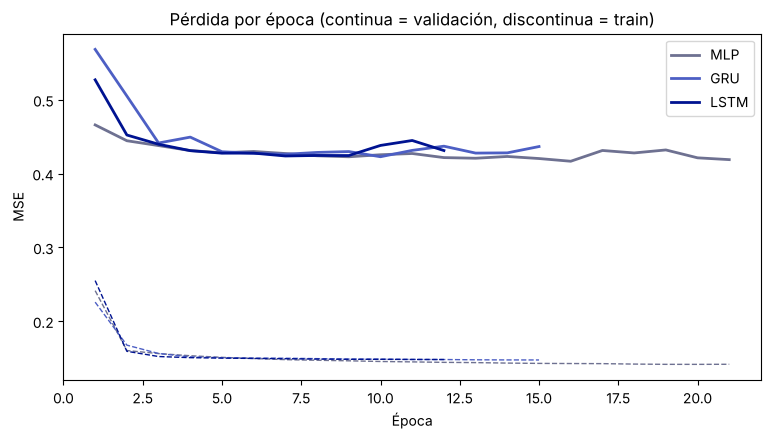

In [8]:
color_modelo = {"MLP": COLORES["gris_medio"], "GRU": COLORES["azul_claro"], "LSTM": COLORES["azul_principal"],
                "LSTM medias geom.": COLORES["acento"], "GRU medias geom.": COLORES["acento"]}

plt.figure(figsize=(9, 4.5))
for nombre, h in historias.items():
    plt.plot(range(1, len(h["train"]) + 1), h["train"], color=color_modelo[nombre], ls="--", lw=1)
    plt.plot(range(1, len(h["val"]) + 1), h["val"], color=color_modelo[nombre], lw=2, label=nombre)
plt.xlabel("Época"); plt.ylabel("MSE"); plt.title("Pérdida por época (continua = validación, discontinua = train)")
plt.legend()
plt.show()

## 7. Valor de referencia: Montecarlo anidado

Para saber cuánto vale de verdad la opción en el trimestre t de un camino, simulamos 2.000 futuros nuevos desde ese punto y hacemos la media del payoff descontado. Lo hacemos para 200 caminos del test y para los 20 trimestres (4.000 valoraciones). Es justo el cálculo caro que la red quiere evitar, así que también medimos cuánto tarda.

La media geométrica junta lo que ya ha pasado (los logs hasta t) con lo que falta por simular, que es lo que hace la función.

In [9]:
M_ANIDADO = 2_000

def valor_montecarlo(camino, t, rng, M=M_ANIDADO):
    # Valor de la opción en el trimestre t, sabiendo el camino hasta t. camino: (20, 3), solo se usan los t primeros
    visto = np.log(camino[:t]).sum(axis=0)                   # suma de logs ya conocida: (3,)
    k = n_times - t
    if k == 0:
        return max(np.exp(visto / n_times).sum() - E, 0)
    futuro = camino[t - 1] * np.cumprod(factores(rng, (M, k)), axis=1)   # (M, k, 3)
    G_sim = np.exp((visto + np.log(futuro).sum(axis=1)) / n_times)       # (M, 3)
    return np.exp(-mu * k * dt) * np.maximum(G_sim.sum(axis=1) - E, 0).mean()

rng_ref = np.random.default_rng(7)
test_idx = np.flatnonzero(filas["test"])
muestra = rng_ref.choice(test_idx, 200, replace=False)

inicio = time.perf_counter()
referencia = np.array([[valor_montecarlo(X[i], t, rng_ref) for t in pasos] for i in muestra])   # (200, 20)
tiempo_mc = time.perf_counter() - inicio
print(f"Montecarlo anidado: {referencia.size} valoraciones en {tiempo_mc:.1f} s")

Montecarlo anidado: 4000 valoraciones en 9.1 s


## 8. Comparación de modelos

Comparamos cada red con el valor de referencia en los 200 caminos y los 20 trimestres: RMSE, MAE y R². También medimos cuánto tarda cada red en dar esos mismos 4.000 valores.

In [10]:
def predecir(modelo, entrada, idx):
    x = a_tensor((entrada_mlp if entrada == "mlp" else entrada_rnn)[idx])
    with torch.no_grad():
        return modelo(x).numpy()

def metricas(pred, ref):
    err = pred - ref
    return {"RMSE": np.sqrt((err**2).mean()), "MAE": np.abs(err).mean(),
            "R2": 1 - (err**2).sum() / ((ref - ref.mean())**2).sum()}

predicciones, filas_tabla = {}, []
for nombre, modelo in modelos.items():
    entrada = "mlp" if nombre == "MLP" else "rnn"
    inicio = time.perf_counter()
    predicciones[nombre] = predecir(modelo, entrada, muestra)[..., 0]           # (200, 20)
    t_pred = time.perf_counter() - inicio
    filas_tabla.append({"modelo": nombre, "parámetros": n_parametros(modelo), **metricas(predicciones[nombre], referencia),
                        "entreno (s)": tiempos_entreno[nombre], "tiempo 4.000 valores (s)": t_pred,
                        "veces más rápido que MC": tiempo_mc / t_pred})
tabla_modelos = pd.DataFrame(filas_tabla).set_index("modelo")
tabla_modelos.round(4)

,parámetros,RMSE,MAE,R2,entreno (s),tiempo 4.000 valores (s),veces más rápido que MC
modelo,,,,,,,
MLP,4737,0.0716,0.0427,0.9825,28.0360,0.0020,4611.7124
GRU,38273,0.0673,0.0428,0.9845,147.6566,0.0114,798.8120
LSTM,51009,0.0636,0.0407,0.9862,108.3386,0.0066,1382.8750


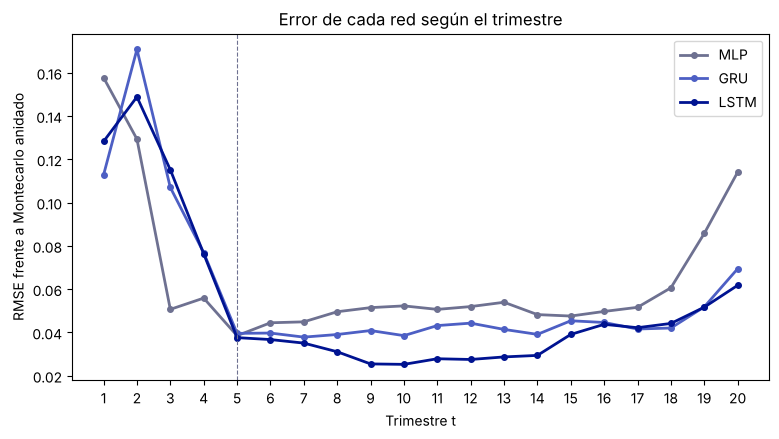

In [11]:
plt.figure(figsize=(9, 4.5))
for nombre, pred in predicciones.items():
    rmse_t = np.sqrt(((pred - referencia)**2).mean(axis=0))
    plt.plot(pasos, rmse_t, marker="o", ms=4, color=color_modelo[nombre], lw=2, label=nombre)
plt.axvline(n_comunes, color=COLORES["gris_medio"], lw=0.8, ls="--")
plt.xlabel("Trimestre t"); plt.ylabel("RMSE frente a Montecarlo anidado"); plt.title("Error de cada red según el trimestre")
plt.xticks(pasos); plt.legend()
plt.show()

Mejor modelo por RMSE: LSTM


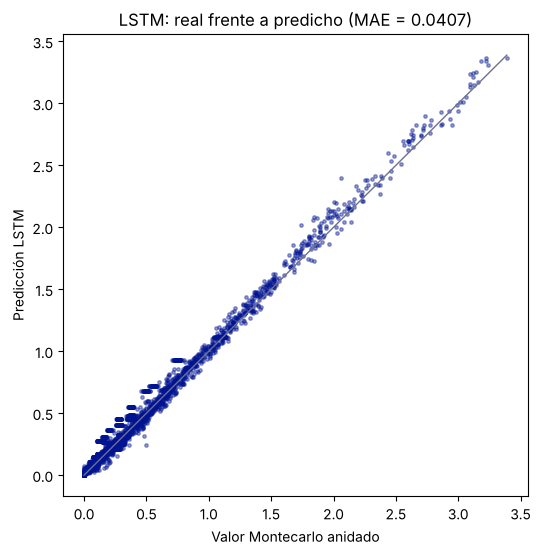

In [12]:
mejor = tabla_modelos["RMSE"].idxmin()
print("Mejor modelo por RMSE:", mejor)

p, r = predicciones[mejor].ravel(), referencia.ravel()
lim = [0, max(p.max(), r.max())]
plt.figure(figsize=(6, 6))
plt.plot(lim, lim, color=COLORES["gris_medio"], lw=1)
plt.scatter(r, p, s=6, color=COLORES["azul_principal"], alpha=0.4)
plt.xlabel("Valor Montecarlo anidado"); plt.ylabel(f"Predicción {mejor}")
plt.title(f"{mejor}: real frente a predicho (MAE = {np.abs(p - r).mean():.4f})")
plt.show()

### Tabla de predicción del valor presente en el momento t

Es el output que pide el reto: para un camino del test, el valor de la opción en cada trimestre según Montecarlo anidado y según cada red.

In [13]:
camino = 0   # primero de los 200 caminos de la muestra
tabla_pred = pd.DataFrame({"t (trimestre)": pasos, "Montecarlo anidado": referencia[camino]})
for nombre, pred in predicciones.items():
    tabla_pred[nombre] = pred[camino]
tabla_pred.set_index("t (trimestre)").round(4)

,Montecarlo anidado,MLP,GRU,LSTM
t (trimestre),,,,
1,0.3753,0.5946,0.4908,0.4795
2,0.2793,0.5151,0.4463,0.4565
3,0.1622,0.2383,0.2474,0.2662
4,0.5559,0.6241,0.7154,0.7164
5,0.5953,0.6705,0.6215,0.5858
6,0.7399,0.7434,0.6680,0.6685
7,0.7962,0.8996,0.7875,0.7607
8,1.1321,1.1105,1.1414,1.1058
9,1.2717,1.3383,1.3789,1.3208


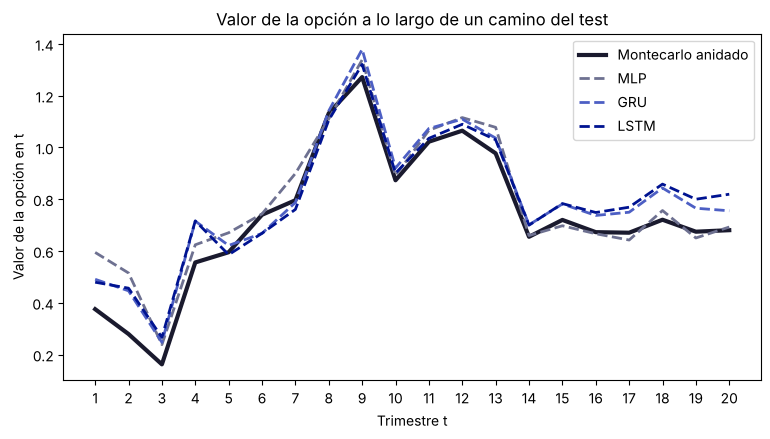

In [14]:
plt.figure(figsize=(9, 4.5))
plt.plot(pasos, referencia[camino], color=COLORES["gris_oscuro"], lw=3, label="Montecarlo anidado")
for nombre, pred in predicciones.items():
    plt.plot(pasos, pred[camino], color=color_modelo[nombre], lw=2, ls="--", label=nombre)
plt.xlabel("Trimestre t"); plt.ylabel("Valor de la opción en t"); plt.title("Valor de la opción a lo largo de un camino del test")
plt.xticks(pasos); plt.legend()
plt.show()

## 9. Objetivo alternativo: predecir las medias geométricas

La otra opción era que la red predijera las tres medias geométricas finales y calcular después el payoff con la fórmula: $\max(\hat G_1 + \hat G_2 + \hat G_3 - E, 0)$ descontado. La entrenamos con la misma topología que el mejor modelo, cambiando solo la salida (3 valores en vez de 1).

Esperamos que **infravalore** la opción. Con MSE, la red aprende la media esperada de $G$, y aplicar el máximo a la media no es lo mismo que hacer la media del máximo (desigualdad de Jensen): $\max(E[\Sigma G] - 3, 0) \le E[\max(\Sigma G - 3, 0)]$. En el Montecarlo del Hito 1, $E[\Sigma G] = 3{,}136$, así que la fórmula aplicada a la media daría 0,129, frente a una prima de 0,301.

In [15]:
objetivo_G = {parte: a_tensor(np.broadcast_to(G[f][:, None, :], (f.sum(), n_times, 3))) for parte, f in filas.items()}
entrada = "mlp" if mejor == "MLP" else "rnn"
nombre_G = f"{mejor} medias geom."
modelo_G, historia_G, t_G = entrenar(mejor, entrada, objetivo_G, n_salidas=3, sufijo="_medias")

G_pred = predecir(modelo_G, entrada, muestra)                                    # (200, 20, 3)
pred_G = np.maximum(G_pred.sum(axis=2) - E, 0) * descuento[None, :]              # payoff con la fórmula
predicciones[nombre_G] = pred_G

comparacion = pd.DataFrame([{"objetivo": f"Valor presente directo ({mejor})", **metricas(predicciones[mejor], referencia),
                             "valor medio predicho": predicciones[mejor].mean()},
                            {"objetivo": f"Medias geométricas → fórmula ({mejor})", **metricas(pred_G, referencia),
                             "valor medio predicho": pred_G.mean()}]).set_index("objetivo")
print(f"Valor medio de referencia: {referencia.mean():.4f}")
comparacion.round(4)

LSTM_medias | época  1 | train 0.1457 | val 0.2185


LSTM_medias | época  2 | train 0.0809 | val 0.1687


LSTM_medias | época  3 | train 0.0732 | val 0.1585


LSTM_medias | época  4 | train 0.0709 | val 0.1548


LSTM_medias | época  5 | train 0.0699 | val 0.1532


LSTM_medias | época  6 | train 0.0693 | val 0.1522


... (5 outputs left out)

LSTM_medias | época 12 | train 0.0676 | val 0.1550


LSTM_medias | época 13 | train 0.0674 | val 0.1544


LSTM_medias | época 14 | train 0.0674 | val 0.1592
  Early stopping
Valor medio de referencia: 0.3655


,RMSE,MAE,R2,valor medio predicho
objetivo,,,,
Valor presente directo (LSTM),0.0636,0.0407,0.9862,0.3948
Medias geométricas → fórmula (LSTM),0.0879,0.0541,0.9736,0.3309


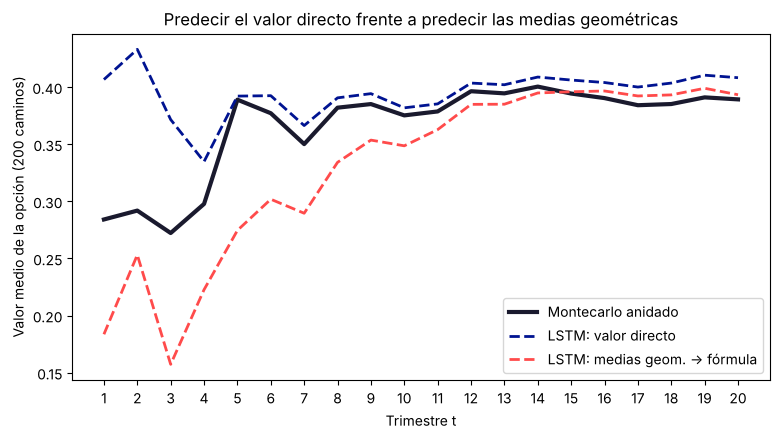

In [16]:
plt.figure(figsize=(9, 4.5))
plt.plot(pasos, referencia.mean(axis=0), color=COLORES["gris_oscuro"], lw=3, label="Montecarlo anidado")
plt.plot(pasos, predicciones[mejor].mean(axis=0), color=color_modelo[mejor], lw=2, ls="--", label=f"{mejor}: valor directo")
plt.plot(pasos, pred_G.mean(axis=0), color=COLORES["acento"], lw=2, ls="--", label=f"{mejor}: medias geom. → fórmula")
plt.xlabel("Trimestre t"); plt.ylabel("Valor medio de la opción (200 caminos)")
plt.title("Predecir el valor directo frente a predecir las medias geométricas")
plt.xticks(pasos); plt.legend()
plt.show()

## 10. Comprobación con el comienzo del Hito 1

Rehacemos el Montecarlo de **montecarlo_verdeclaro.ipynb** con su semilla 11. Ese comienzo no está entre los 50 del entrenamiento, así que la red no lo ha visto nunca. En el trimestre 5 todo el futuro está por simular, y el valor de la opción es el payoff medio de las 100.000 simulaciones traído al trimestre 5.

In [17]:
rng11 = np.random.default_rng(11)
S1 = np.cumprod(np.vstack([S0, factores(rng11, (n_comunes,))]), axis=0)               # (6, 3)
S2 = S1[-1] * np.cumprod(factores(rng11, (100_000, n_resto)), axis=1)                 # (100.000, 15, 3)
X_h1 = np.concatenate([np.broadcast_to(S1[1:], (100_000, n_comunes, 3)), S2], axis=1)
payoff_h1 = np.maximum(np.exp(np.log(X_h1).mean(axis=1)).sum(axis=1) - E, 0)

valor_t5_mc = payoff_h1.mean() * np.exp(-mu * n_resto * dt)
print(f"Prima de hoy (Hito 1): {payoff_h1.mean() * np.exp(-mu * T):.4f}")

x = np.log(X_h1[:1])                                                                # basta un camino: hasta t=5 son todos iguales
x_mlp = np.concatenate([x, np.cumsum(x, axis=1) / pasos[None, :, None], (pasos / n_times)[None, :, None]], axis=2)
fila = {"Montecarlo (100.000 sims)": valor_t5_mc}
with torch.no_grad():
    for nombre, modelo in modelos.items():
        fila[nombre] = modelo(a_tensor(x_mlp if nombre == "MLP" else x))[0, n_comunes - 1, 0].item()
pd.Series(fila, name="valor de la opción en t = 5").round(4)

Prima de hoy (Hito 1): 0.3014


Montecarlo (100.000 sims)    0.3052
MLP                          0.2940
GRU                          0.2741
LSTM                         0.2708
Name: valor de la opción en t = 5, dtype: float64

## Conclusiones y siguientes pasos

- **Qué aprende la red:** el valor de la opción en cada trimestre a partir del camino visto hasta ese momento. Montecarlo necesita miles de simulaciones nuevas para cada camino y cada trimestre.
- **Topología:** comparamos una red densa a la que le damos el resumen del camino (MLP) con dos recurrentes que tienen que recordarlo ellas (GRU y LSTM). La tabla del apartado 8 dice cuál gana en error y en tiempo.
- **Objetivo:** predecir las medias geométricas y aplicar la fórmula después infravalora la opción (Jensen). Por eso la red predice directamente el valor presente.
- **Pendiente:**
  - Issue 17: probar hiperparámetros del mejor modelo (neuronas, capas, lr, batch, Dropout, scheduler).
  - Issue 19: validación cruzada k-fold por comienzo.
  - Issue 18: comparación con la fórmula cerrada y la de BBVA.